# Case study 3 · Invoice processing

**The question a finance team asks:** do we need a large model to extract booking data from our
invoices, or does a small one do the job? And do the other steps of the pipeline matter: how the
PDF is turned into text, and whether a second step checks the result?

**The setup:** 106 invoices from the Invoice Extraction Benchmark (synthetic but realistic
invoices from the US, UK, EU and southern Africa, including credit notes, mixed currencies and
multi-page invoices). The system reads each PDF, turns it into text, and extracts the booking data
as JSON. Three factors:

| Factor | Levels |
|---|---|
| `model` | `gemma-3-4b` · `gpt-oss-20b` · `gemma-4-31b` · `gpt-oss-120b` · `deepseek-v4-pro` |
| `pdf_text` | `with_layout` (columns stay aligned) · `without_layout` (plain reading order, pypdf's default) |
| `prompting` | `extract_only` · `extract_then_check` (a second call checks and corrects the result) |

That gives 5 × 2 × 2 = **20 configurations × 106 invoices = 2,120 extractions**. An invoice counts
as **ready to book** only if every extracted field is right.

**What this study shows in CAFE:** black-box mode (the system is ordinary code that knows nothing
about CAFE), a judge written in plain code instead of an LLM, a correct/wrong rubric analysed with
the logistic mixed model, filters by invoice category, and the cost and energy of each model.

In [1]:
import json

import pandas as pd

import cafe

cafe.load_env();   # the API keys from the repo's .env

## 1 · The data

The invoices and their correct booking data (created once by `data/prepare_data.py`). The
`category` (clean, currency, tax, credit_note, freight, multipage, hard) and `difficulty` become
filters in the web app.

In [2]:
from invoice_system import INVOICE_FOLDER, pdf_to_text

invoices = json.load(open("data/correct_fields.json"))

dataset = [
    {
        "id": invoice["id"],
        # the invoice as text, so it can be read next to every answer in the web app
        # (the system itself reads the PDF)
        "text": pdf_to_text(pdf_path=INVOICE_FOLDER / f"{invoice['id']}.pdf", keep_layout=True),
        "reference": json.dumps(invoice["correct_fields"], indent=1),
        "category": invoice["category"],
        "difficulty": invoice["difficulty"],
    }
    for invoice in invoices
]

print(f"{len(dataset)} invoices. The correct booking data of the first one:")
print(dataset[0]["reference"])

106 invoices. The correct booking data of the first one:
{
 "vendor_name": "Acme Industrial Supply Co",
 "document_number": "ACM-100145",
 "invoice_date": "2024-03-12",
 "currency": "USD",
 "tax": 25.99,
 "total": 372.49,
 "document_type": "invoice"
}


## 2 · The system

The invoice pipeline lives in [`invoice_system.py`](invoice_system.py): PDF → text → extract →
(optionally) check. It is plain Python with no CAFE inside, like an existing company system. CAFE
only calls `process_invoice(config, invoice)` and reads what it returns: the extracted data plus
the cost, tokens and energy the system reports about itself.

Here is what the two `pdf_text` options make of the same invoice:

In [3]:
example = INVOICE_FOLDER / "currency-dual-usd-nad-4.pdf"
print("── with_layout ──\n", pdf_to_text(pdf_path=example, keep_layout=True)[:1500])
print("\n── without_layout ──\n", pdf_to_text(pdf_path=example, keep_layout=False)[:700])

── with_layout ──
                  Kunene Clearing & Forwarding (Pty) Ltd
                                             325 Hage Geingob Street
                                                      Windhoek
                          Tel +264 80 555 0484 | billing@kuneneclearingforw.com.na
                                              VAT Reg No: 4139321248
                                                  INVOICE

Invoice #:           F-26-9064                              PO Number:            4500421384
Date:                16/03/2026                             Terms:                30 days
Due Date:            15/04/2026                             Currency:             USD


BILL TO
Etosha Gate Engineering Supplies CC
510 Nickel Street
Swakopmund
VAT Reg No: 4880697625


Description                                                    Qty       Unit USD      Amount USD        Amount NAD
Documentation fee                                                 1         26.02            26.0

In [4]:
from invoice_system import MODELS, process_invoice

## 3 · The factors

In black-box mode the factors are simply names and levels; the system reads them from its config.

In [5]:
factors = [
    cafe.Factor(name="model", levels=list(MODELS)),
    cafe.Factor(name="pdf_text", levels=["with_layout", "without_layout"]),
    cafe.Factor(name="prompting", levels=["extract_only", "extract_then_check"]),
]

## 4 · Rubric and judge

Two outcomes: the invoice is ready to book, or someone has to correct it. Because the rubric is
binary, CAFE analyses it with a logistic mixed model.

The judge is plain code ([`invoice_judge.py`](invoice_judge.py)): it compares every field with the
correct value, tolerating differences that don't matter (date and number formats, upper/lower case,
legal forms like "Ltd", currency symbols). Its reasoning lists the wrong fields.

In [6]:
from invoice_judge import FieldCheckJudge

ready_to_book = cafe.Rubric(
    name="ready_to_book",
    scale_type=cafe.ScaleType.binary,
    levels=[
        cafe.Level(value=0, label="needs_correction", description="At least one field is wrong: someone has to fix it before booking."),
        cafe.Level(value=1, label="ready_to_book", description="Every checked field is correct: the invoice can be booked as extracted."),
    ],
    instruction="Check whether every extracted field matches the correct booking data.",
)

judge = FieldCheckJudge()

## 5 · Run the study

First the plan and a quick preflight (one invoice through every configuration, with a time and
cost estimate), then the full run. The run saves its progress as it goes: if it is interrupted,
or some extractions failed (e.g. a provider was briefly rate-limited), running the cell again
continues where it stopped and retries only the failed ones.

In [7]:
# A study = the system, the factors to vary, the inputs, and how to score the answers.
study = cafe.Study(
    name="invoice-processing",
    system=process_invoice,
    factors=factors,
    dataset=dataset,
    rubric=ready_to_book,
    judge=judge,
)

print(study.plan())        # how many configurations, answers and judge calls (nothing runs yet)
print(study.preflight(concurrency=4))   # one input through every configuration: errors, time, cost

{'name': 'invoice-processing', 'design': 'full_factorial', 'factors': ['model', 'pdf_text', 'prompting'], 'configs': 20, 'items': 106, 'replications': 1, 'runs': 2120, 'judged': True, 'judge_calls': 2120}


Preflight(answers=Results(invoice-processing: 20 answers, 20 configs, 0 errors), estimate={'sampled_cells': 20, 'total_cells': 2120, 'est_total_compute_s': 6792.08, 'est_total_cost_usd': 0.806, 'labels': ['model=gemma-3-4b·pdf_text=without_layout·prompting=extract_only']}, warnings=[], judge_calls=2120)


In [8]:
# Run every invoice through every configuration, judge every answer, then fit the statistics.
result = study.evaluate(
    concurrency=4,   # 4 at a time: Ollama Cloud rejects too many parallel requests
    checkpoint_path="results/extractions.cafe.jsonl",
    judge_checkpoint_path="results/verdicts.cafe.jsonl",
)

invoice-processing: answers: 100%  2120/2120 [41:02<00:00,  1.16s/it]


judging: 100%  2120/2120 [00:01<00:00, 1163.81it/s]


## 6 · The results

The full report: share of invoices ready to book per configuration, attribution (which factor
explains how much), and the logistic mixed model with one test per factor.

In [9]:
print(result.report())

2120 answers · 20 configs · 106 inputs · 2120 ratings · best: model=deepseek-v4-pro·pdf_text=with_layout·prompting=extract_then_check

pipeline: 2120 answers  →  2120 judged  →  2120 usable verdict(s)

────────────────────────────────────────────────────────────
DESCRIPTIVE — means & best configuration
────────────────────────────────────────────────────────────
verdicts: 2120   factors: model, pdf_text, prompting

overall mean quality: 0.91  (n=2120)

per-configuration mean quality:
  0.98  (n=106)  model=deepseek-v4-pro·pdf_text=with_layout·prompting=extract_then_check
  0.98  (n=106)  model=deepseek-v4-pro·pdf_text=without_layout·prompting=extract_only
  0.98  (n=106)  model=deepseek-v4-pro·pdf_text=without_layout·prompting=extract_then_check
  0.98  (n=106)  model=gemma-4-31b·pdf_text=with_layout·prompting=extract_then_check
  0.98  (n=106)  model=gemma-4-31b·pdf_text=without_layout·prompting=extract_then_check
  0.98  (n=106)  model=gpt-oss-120b·pdf_text=with_layout·prompting=extr

Does the checking step help every model, or only some?

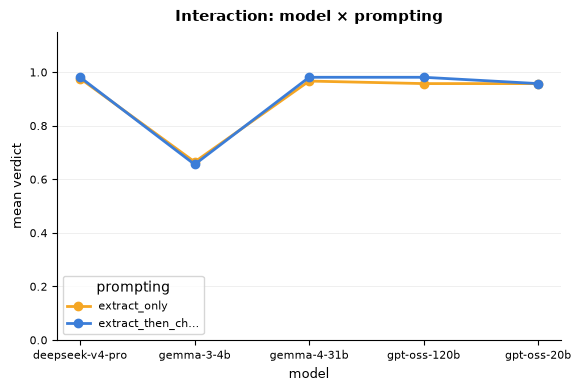

In [10]:
result.plot(kind="interaction", factors=["model", "prompting"]);

Does keeping the layout matter, and for which models?

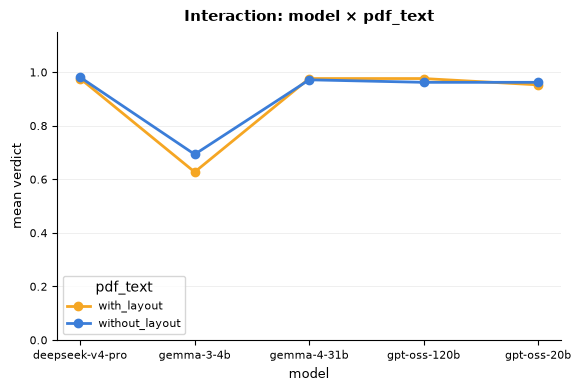

In [11]:
result.plot(kind="interaction", factors=["model", "pdf_text"]);

Quality against cost: the configurations on the Pareto front are the only ones worth considering.

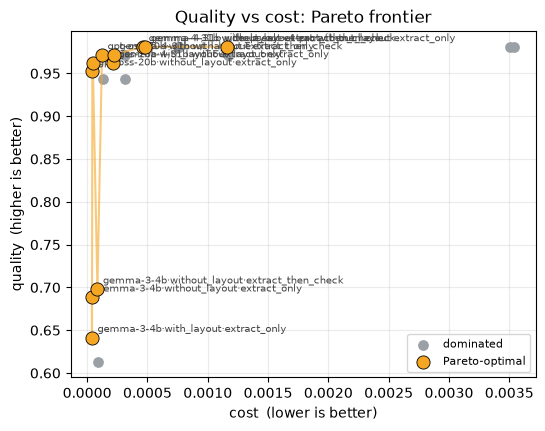

In [12]:
result.plot(kind="pareto");

Share of invoices ready to book, per invoice category and model: where do the small models fail?

In [13]:
extractions = pd.DataFrame(result.records())
category = {item["id"]: item["category"] for item in dataset}
extractions["category"] = extractions["input_id"].map(category)
extractions.pivot_table(index="category", columns="model", values="verdict", aggfunc="mean").round(2)

model,deepseek-v4-pro,gemma-3-4b,gemma-4-31b,gpt-oss-120b,gpt-oss-20b
category,,,,,
clean,1.00,0.62,1.00,1.00,0.99
credit_note,1.00,0.75,1.00,1.00,1.00
currency,0.99,0.57,0.96,0.93,0.91
freight,1.00,0.73,1.00,1.00,0.98
hard,1.00,0.64,1.00,1.00,1.00
multipage,1.00,0.62,1.00,1.00,0.98
tax,0.86,0.75,0.86,0.86,0.86


Cost, energy and time per model, summed over all its extractions:

In [14]:
extractions.groupby("model")[["cost_usd", "energy_wh", "elapsed_s"]].sum().round(4)

,cost_usd,energy_wh,elapsed_s
model,,,
deepseek-v4-pro,0.9937,395.2340,3033.0618
gemma-3-4b,0.0269,32.5865,820.6519
gemma-4-31b,0.1463,195.8763,761.5681
gpt-oss-120b,0.2270,112.2531,1188.9065
gpt-oss-20b,0.0367,47.9213,4022.3002


## 7 · Save for the web app

One file with everything. In the web app, **Studies → Import study** turns it into a browsable
study; the invoice text, the extracted JSON and the list of wrong fields are shown side by side.

In [15]:
cafe.save_evaluation(evaluation=result, path="results/invoice_processing_results.json")